In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy as sc

In [2]:
N = 1000
dt = 0.01
t = np.arange(N)*dt

#### Aliasing

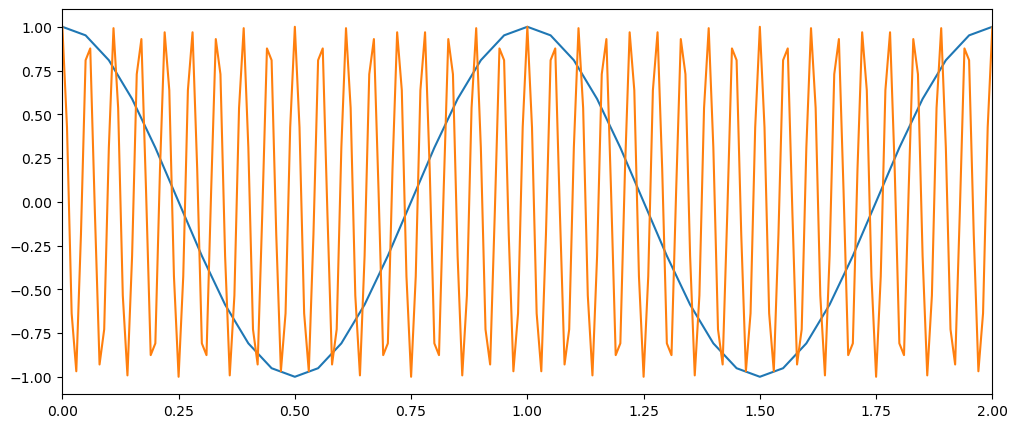

In [3]:
N_sample = 200
N_unaliased = 1000
t = 10
dt = t/N_sample
dt_un = t/N_unaliased
t_sample = np.arange(N_sample)*dt
t_unalised = np.arange(N_unaliased)*dt_un

cont_signal = lambda t, freq: np.cos(2*np.pi*freq*t)

freq = 1
discrete_signal = cont_signal(t_sample, freq)
dis_unaliased = cont_signal(t_unalised, 18)

fig, ax = plt.subplots(figsize=(12,5))
ax.plot(t_sample, discrete_signal)
ax.plot(t_unalised, dis_unaliased)
ax.set_xlim(0, 2)
fig.show()

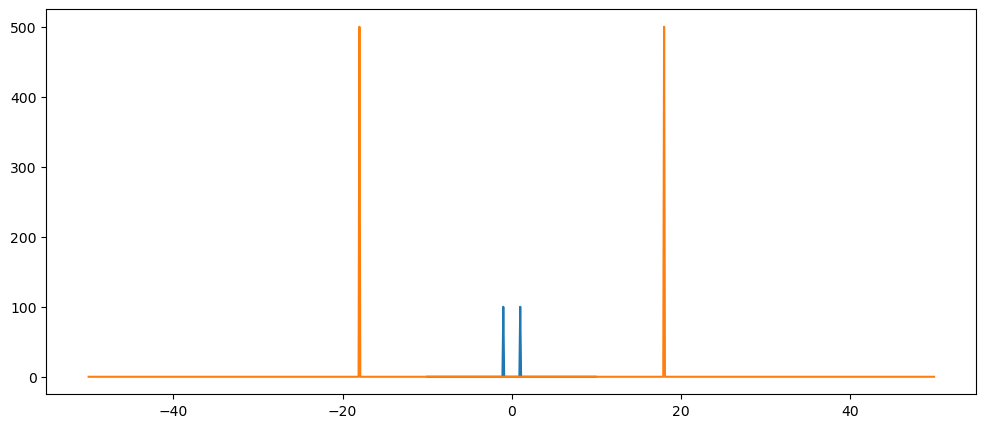

In [4]:
#np.fft?
fft = np.fft.fftshift(np.fft.fft(discrete_signal))
fft_un = np.fft.fftshift(np.fft.fft(dis_unaliased))

plt.figure(figsize=(12,5))
plt.plot(np.fft.fftshift(np.fft.fftfreq(N_sample, dt)), abs(fft))
plt.plot(np.fft.fftshift(np.fft.fftfreq(N_unaliased, dt_un)), abs(fft_un))

#### Other waves

Text(0, 0.5, 'unwrapped phase')

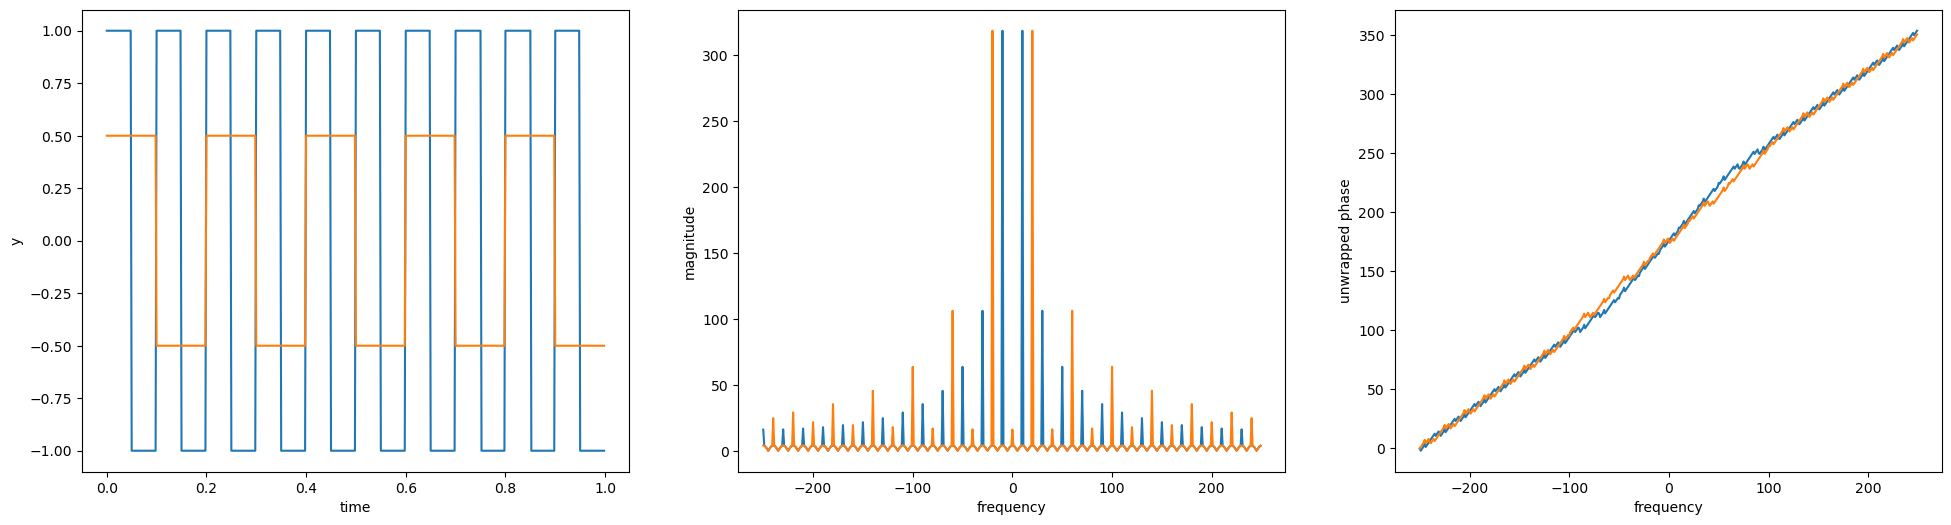

In [5]:
N = 500
t = np.linspace(0, 1, N, endpoint=False)
signal_freq = 10
dt = t[1] - t[0]
def square(t, freq, multiplier=1, offset=0):
    return offset+sc.signal.square(2*np.pi*freq*t)*multiplier
def fft_magn(f, t, freq, multiplier=1, offset=0):
    return np.fft.fftshift(np.fft.fft(f(t, freq)))
def fft_ph(magn):
    return np.angle(magn)

square_1 = square(t, signal_freq)
square_2 = square(t, signal_freq-5, 0.5)
square_3 = square(t, signal_freq+2, 0.3)

fft_magn_sq = np.fft.fftshift(np.fft.fft(square(t, signal_freq)))
fft_freq_sq = np.fft.fftshift(np.fft.fftfreq(N, dt))
fft_ph_sq = np.angle(fft_magn_sq)

fig, axs = plt.subplots(1, 3, figsize=(24,6))
axs[0].plot(t, square_1)
axs[0].plot(t, square_2)
axs[0].set_xlabel('time')
axs[0].set_ylabel('y')
axs[1].plot(fft_freq_sq, abs(fft_magn(square, t, signal_freq)))
axs[1].plot(fft_freq_sq, abs(fft_magn(square, t, signal_freq+10, 0.5)))
axs[1].set_xlabel('frequency')
axs[1].set_ylabel('magnitude')
axs[2].plot(fft_freq_sq, np.unwrap(fft_ph(fft_magn(square, t, signal_freq))))
axs[2].plot(fft_freq_sq, np.unwrap(fft_ph(fft_magn(square, t, signal_freq+10))))
axs[2].set_xlabel('frequency')
axs[2].set_ylabel('unwrapped phase')